In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#bleating_search_file = Path("/home/joselu/Universidad/Doctorado/GENIO/tmp/goat_bleating/individuals.csv")
bleating_search_file = Path("/home/joselu/Universidad/Doctorado/GENIO/tmp/goat_bleating/individuals_20_gen.csv")

bleating_dataframe = pd.read_csv(bleating_search_file)

successful_bleating_dataframe = bleating_dataframe[
    bleating_dataframe["evaluation_status"] == "success"
]

In [3]:
design_columns = ['design.preproccessing_configuration.FFT_size', 'design.preproccessing_configuration.Hop_length', 'design.preproccessing_configuration.MEL_band_number', 'design.preproccessing_configuration.lower_band_limit_hz', 'design.preproccessing_configuration.sample_rate', 'design.preproccessing_configuration.upper_band_limit_hz', 'design.preproccessing_configuration.window_hop_samples', 'design.preproccessing_configuration.window_size_samples']
metric_columns = ['metric.sound_classification.best_val_accuracy', 'metric.sound_classification.f1', 'metric.sound_classification.loss', 'metric.sound_classification.precision', 'metric.sound_classification.recall']
objectives = ['objective.accuracy.raw']

In [4]:
COLUMN_LABELS = {
    "design.preproccessing_configuration.FFT_size": "FFT size",
    "design.preproccessing_configuration.Hop_length": "Hop length",
    "design.preproccessing_configuration.MEL_band_number": "MEL band number",
    "design.preproccessing_configuration.lower_band_limit_hz": "Lower band limit (Hz)",
    "design.preproccessing_configuration.sample_rate": "Sample rate (Hz)",
    "design.preproccessing_configuration.upper_band_limit_hz": "Upper band limit (Hz)",
    "design.preproccessing_configuration.window_hop_samples": "Window hop (samples)",
    "design.preproccessing_configuration.window_size_samples": "Window size (samples)",
    "objective.accuracy.raw": "Accuracy",
    "metric.sound_classification.best_val_accuracy": "Best validation accuracy",
    "metric.sound_classification.f1": "F1 score",
    "metric.sound_classification.loss": "Loss",
    "metric.sound_classification.precision": "Precision",
    "metric.sound_classification.recall": "Recall",
}

def describe_column(column: str) -> str:
    if column in COLUMN_LABELS:
        return COLUMN_LABELS[column]

    technical_name = column.rsplit(".", maxsplit=1)[-1]
    return technical_name.replace("_", " ").title()


def sort_plot_values(values) -> list:
    numeric_values = []
    other_values = []
    for position, value in enumerate(values):
        try:
            numeric_value = float(value)
        except (TypeError, ValueError):
            other_values.append((position, value))
            continue
        if pd.isna(numeric_value):
            other_values.append((position, value))
        else:
            numeric_values.append((numeric_value, position, value))

    numeric_values.sort(key=lambda item: (item[0], item[1]))
    return (
        [value for _, _, value in numeric_values]
        + [value for _, value in other_values]
    )

In [5]:
def plot_design_progression(dataframe: pd.DataFrame, column: str):
    counts = (
        dataframe.groupby(["generation", column], dropna=False)
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    counts = counts.reindex(columns=sort_plot_values(counts.columns))
    ax = counts.plot.area(stacked=True, alpha=0.8, figsize=(10, 6))
    ax.set_xlabel("Generation")
    ax.set_ylabel("Count")
    ax.set_title(f"Evolución poblacional: {describe_column(column)}")
    ax.legend(title=describe_column(column), bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.figure.tight_layout()
    return ax

In [6]:
def plot_value_progression(
    dataframe: pd.DataFrame,
    column: str,
    title: str | None = None,
):
    """Plot the maximum, median and interquartile range by generation."""
    column_label = describe_column(column)
    values = pd.to_numeric(dataframe[column], errors="coerce")

    statistics = (
        pd.DataFrame({"generation": dataframe["generation"], column: values})
        .dropna(subset=["generation", column])
        .groupby("generation")[column]
        .agg(
            q1=lambda generation: generation.quantile(0.25),
            median="median",
            q3=lambda generation: generation.quantile(0.75),
            max="max",
        )
        .sort_index()
    )

    if statistics.empty:
        raise ValueError(
            f"La columna '{column}' no contiene valores numéricos"
        )

    _, ax = plt.subplots(figsize=(10, 6))

    positions = list(range(len(statistics)))

    q1 = statistics["q1"].to_numpy(dtype=float)
    medians = statistics["median"].to_numpy(dtype=float)
    q3 = statistics["q3"].to_numpy(dtype=float)
    maximums = statistics["max"].to_numpy(dtype=float)

    # Interquartile range: Q1-Q3
    ax.fill_between(
        positions,
        q1,
        q3,
        alpha=0.2,
        color="tab:purple",
        label="Interquartile range",
    )

    # Maximum
    ax.plot(positions, maximums, marker="o", linestyle="--", color="tab:green", label="Maximum")

    # Median
    ax.plot(positions, medians, marker="o", linewidth=2, color="tab:purple", label="Median")

    ax.set_xticks(positions)
    ax.set_xticklabels(statistics.index)

    ax.set_xlabel("Generation")

    ax.set_ylabel(column_label)

    ax.set_title(title or f"Progression of {column_label} by generation")
    ax.legend()

    ax.grid(alpha=0.25)

    ax.figure.tight_layout()

    return ax

In [7]:
# Cada fila del CSV es una propuesta de la población, incluso si falló su evaluación.
print("Propuestas por generación:")
display(bleating_dataframe.groupby("generation").size().rename("individuals"))
print("Estado de evaluación por generación:")
display(pd.crosstab(bleating_dataframe["generation"], bleating_dataframe["evaluation_status"]))

Propuestas por generación:


generation
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
13    100
14    100
15    100
16    100
17    100
18    100
19    100
20    100
Name: individuals, dtype: int64

Estado de evaluación por generación:


evaluation_status,failed,success
generation,,
1,60,40
2,21,79
3,40,60
4,21,79
5,17,83
6,24,76
7,47,53
8,28,72
9,23,77


In [8]:
# 1. Encontrar el índice de la fila con el valor máximo
idx_max = bleating_dataframe['metric.sound_classification.best_val_accuracy'].idxmax()

print("Mejor individuo:")
print(bleating_dataframe.loc[idx_max, 'metric.sound_classification.best_val_accuracy'])

print("\nConfiguración del diseño:")
# 2. Imprimir solo el valor de esa fila específica para cada columna de diseño
for column in design_columns:
    print(f"{column}: {bleating_dataframe.loc[idx_max, column]}")


Mejor individuo:
0.8886089324951172

Configuración del diseño:
design.preproccessing_configuration.FFT_size: 2048
design.preproccessing_configuration.Hop_length: 384
design.preproccessing_configuration.MEL_band_number: 136
design.preproccessing_configuration.lower_band_limit_hz: 0
design.preproccessing_configuration.sample_rate: 22050
design.preproccessing_configuration.upper_band_limit_hz: 8000
design.preproccessing_configuration.window_hop_samples: 2000
design.preproccessing_configuration.window_size_samples: 28000


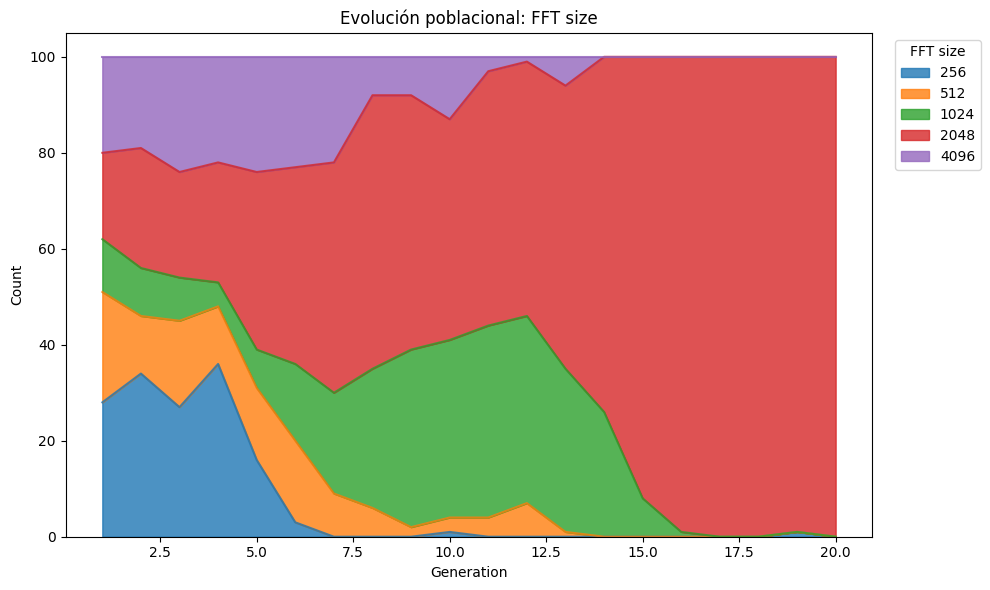

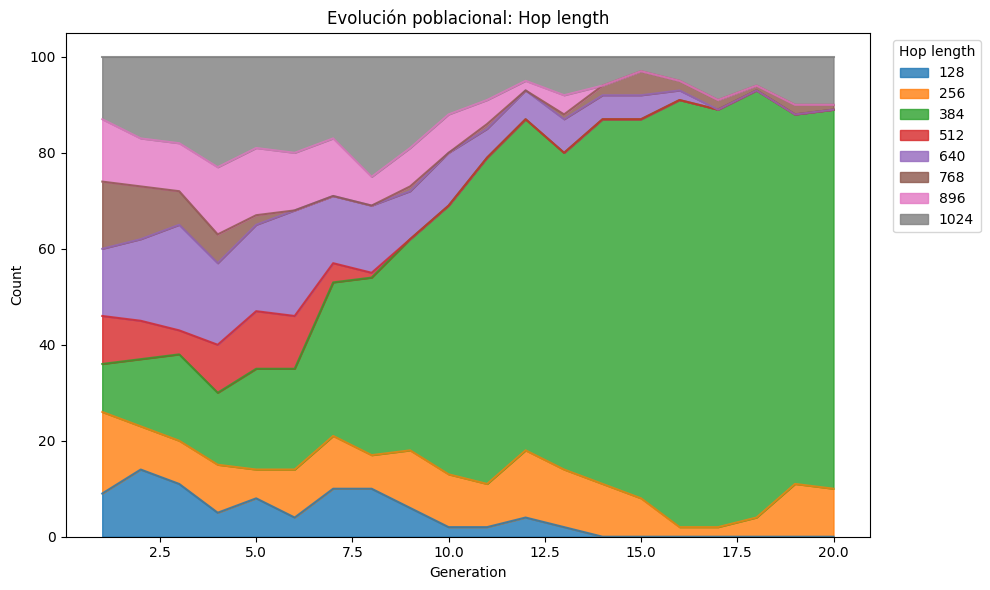

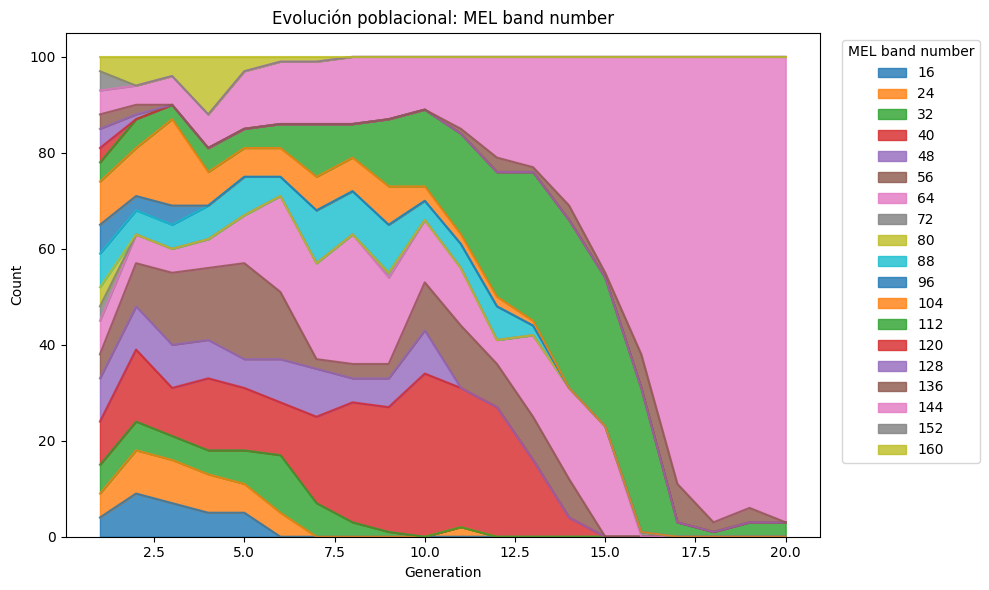

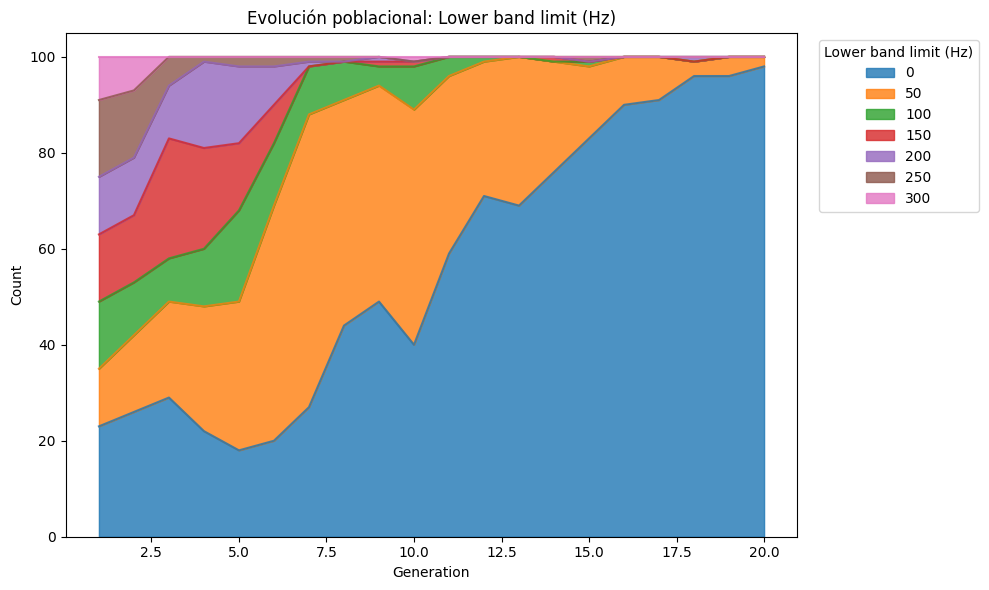

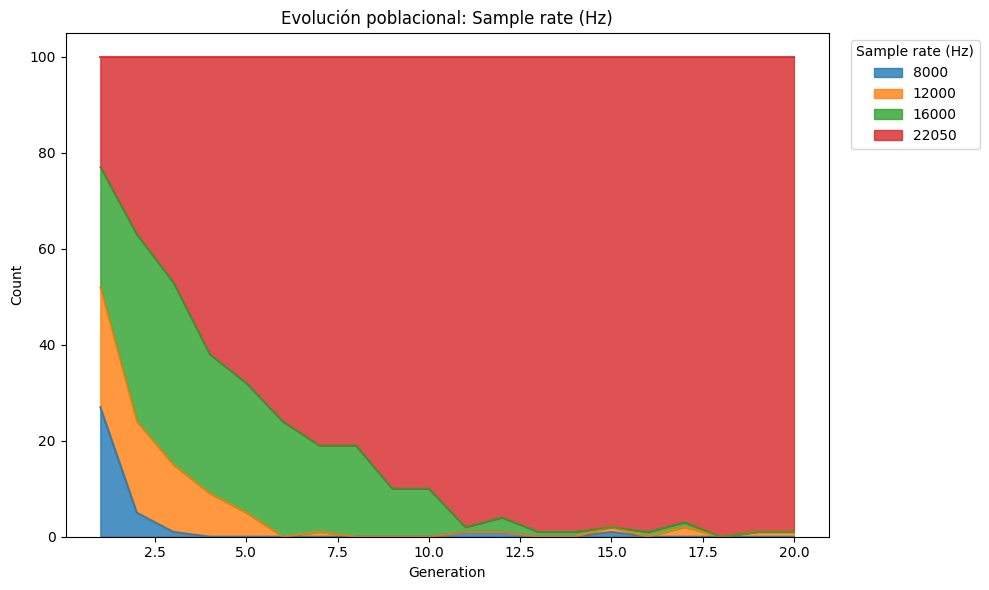

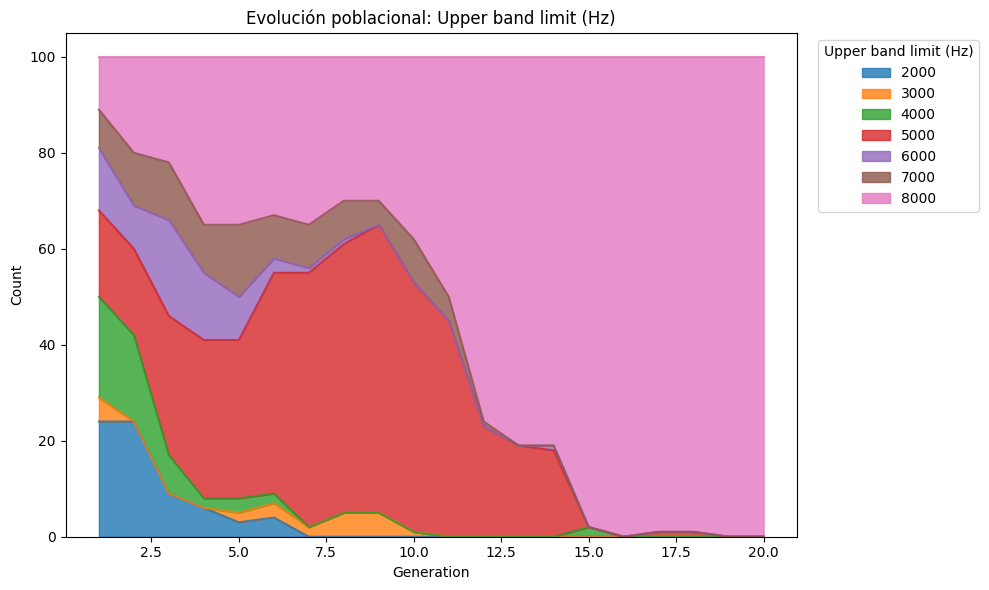

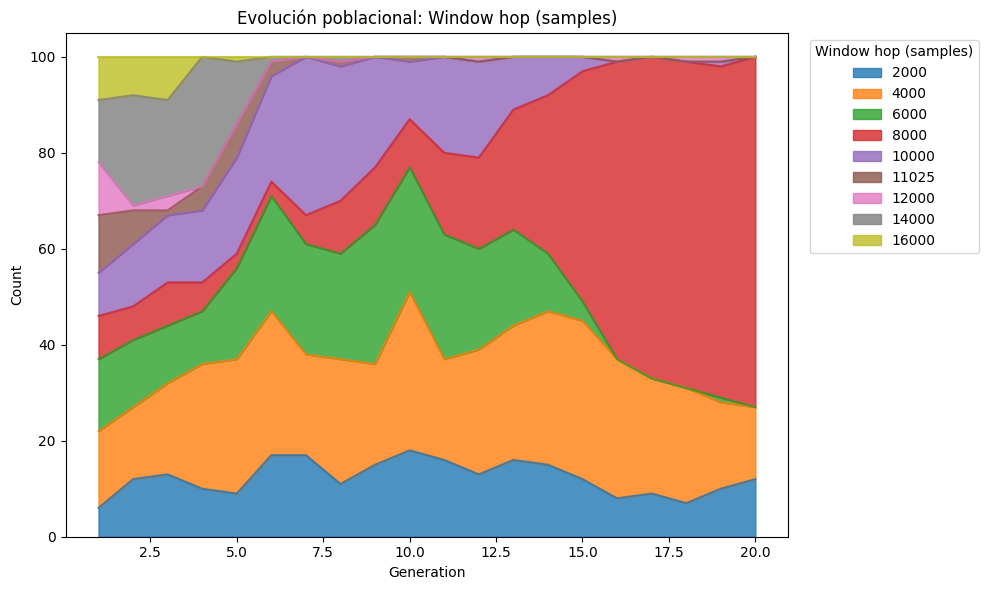

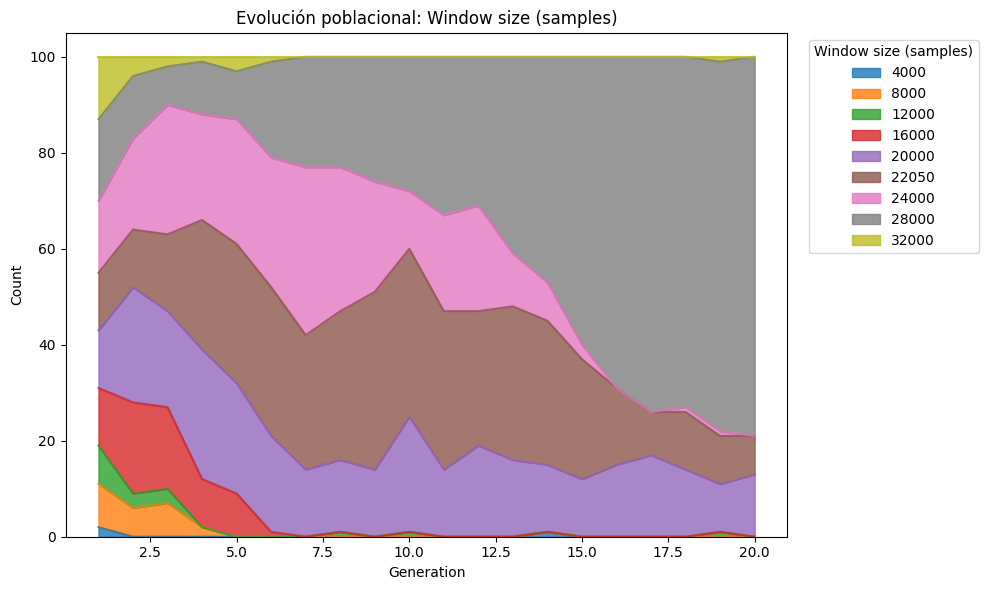

In [9]:
for column in design_columns:
    plot_design_progression(bleating_dataframe, column)
    plt.show()

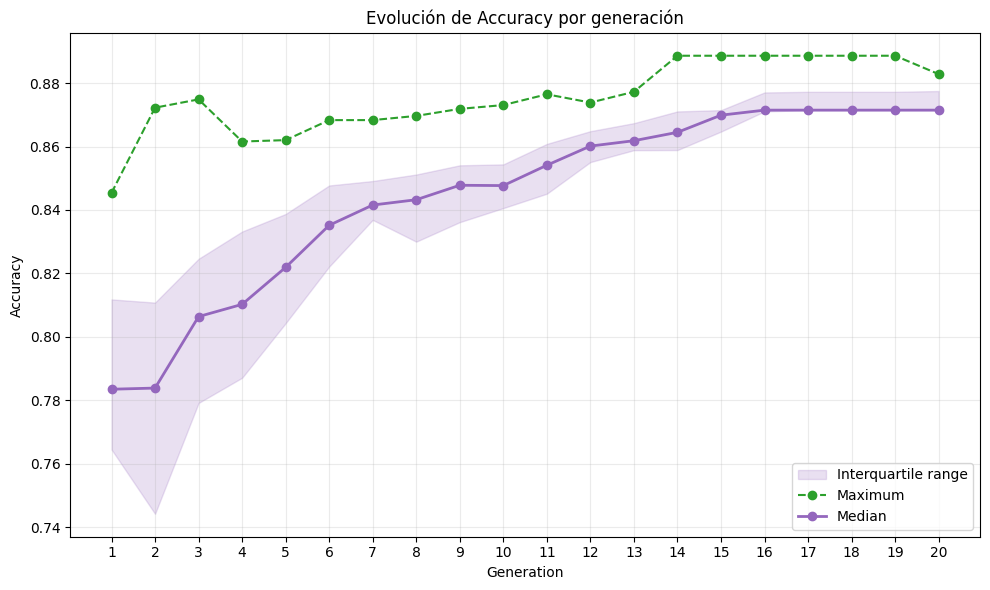

In [10]:
# La precisión solo está disponible para las evaluaciones completadas.
for column in objectives:
    plot_value_progression(
        successful_bleating_dataframe, column,
        title=f"Evolución de {describe_column(column)} por generación",
    )
    plt.show()

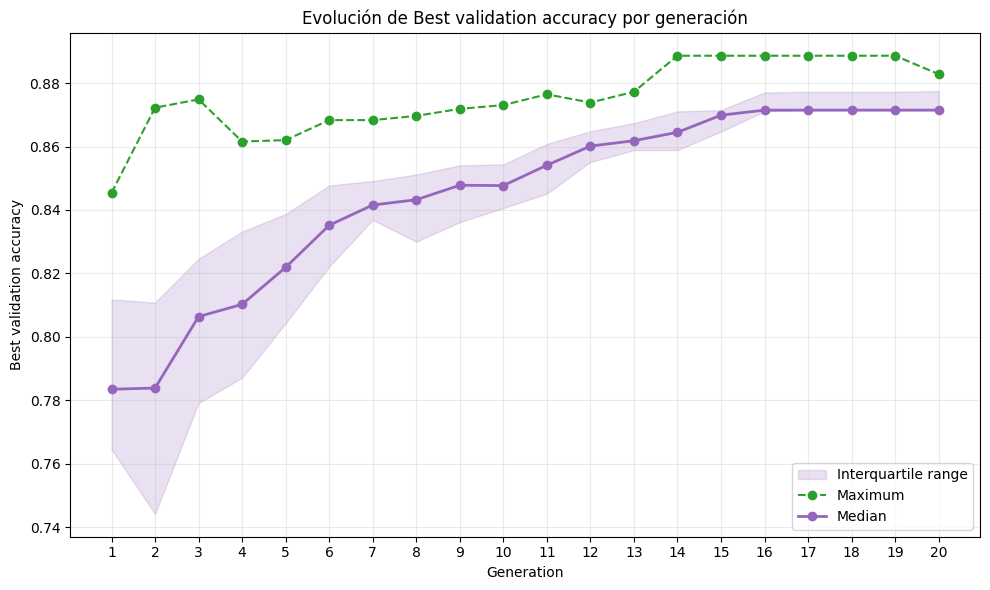

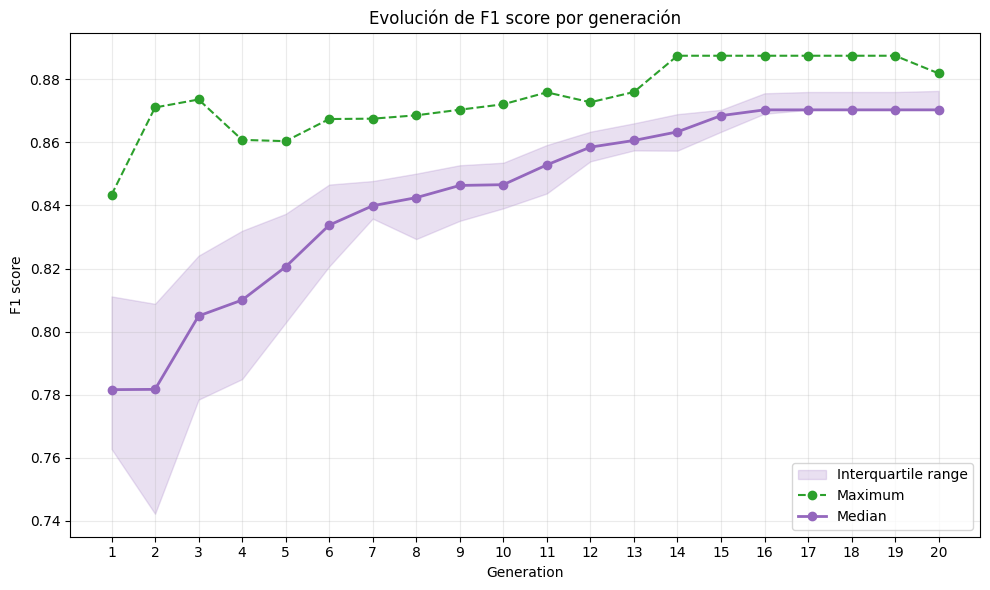

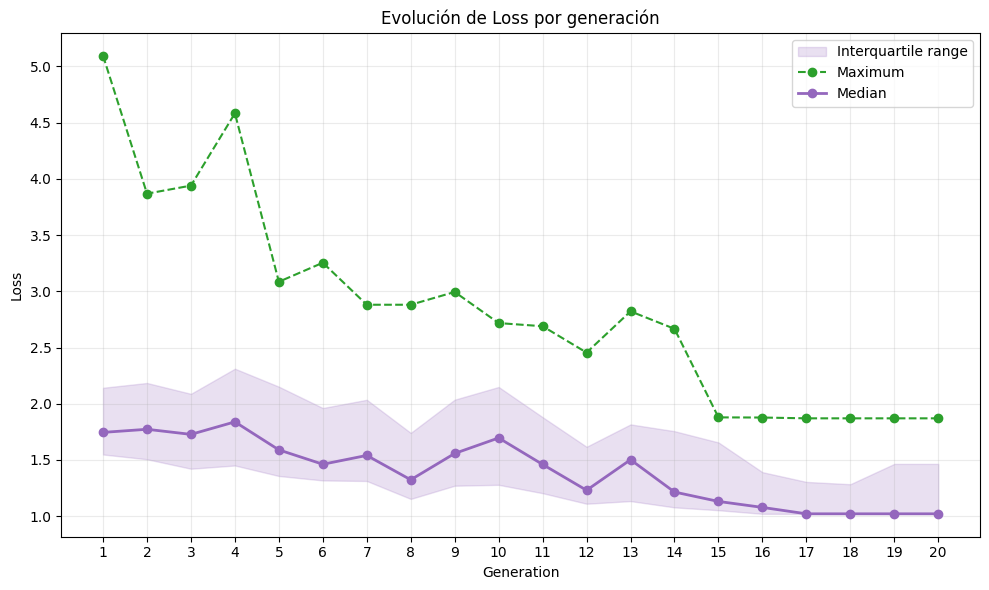

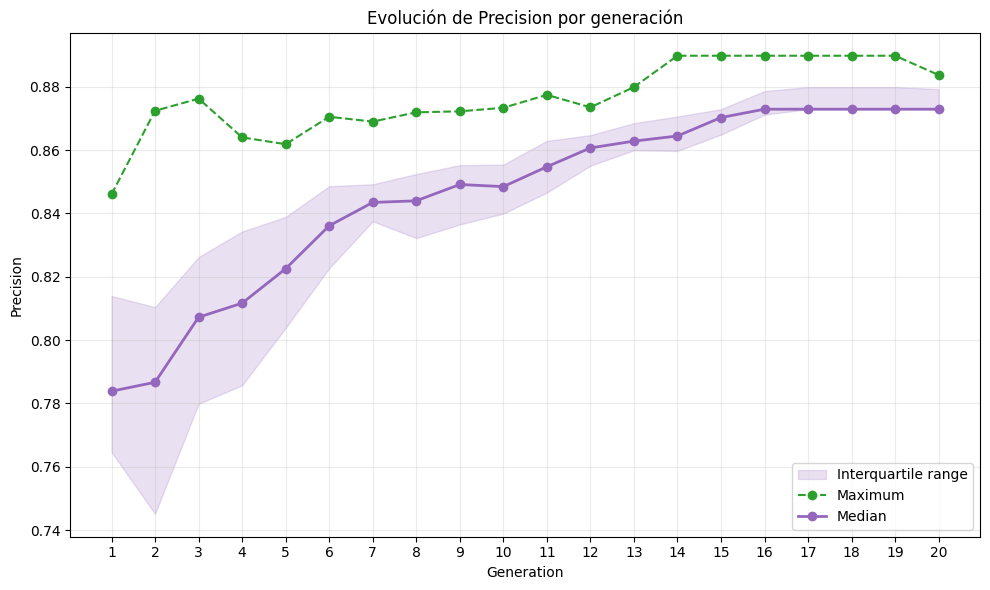

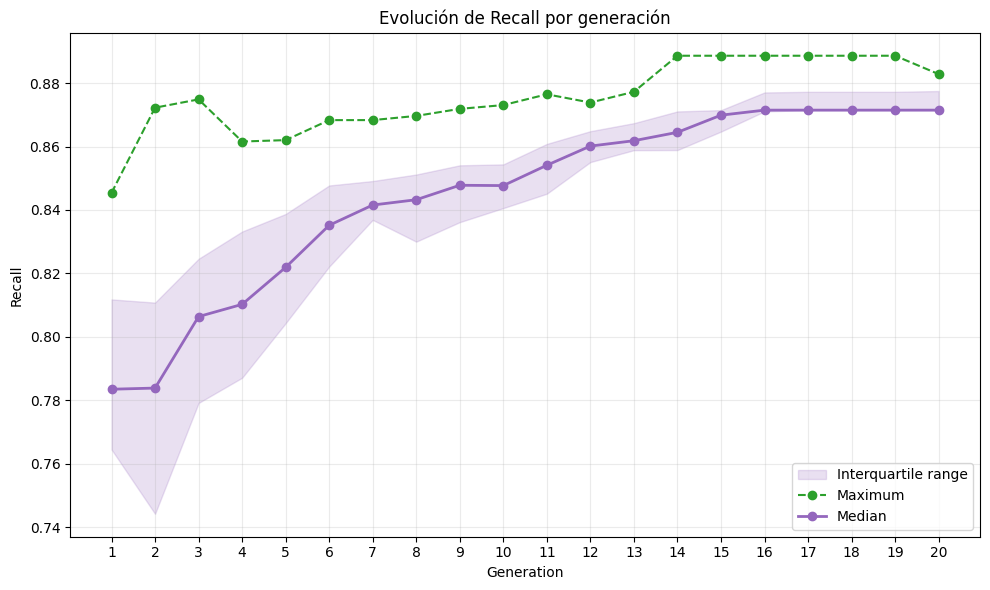

In [11]:
for column in metric_columns:
    plot_value_progression(
        successful_bleating_dataframe, column,
        title=f"Evolución de {describe_column(column)} por generación",
    )
    plt.show()